#### Conclusions



In [16]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

root_path = os.path.dirname(os.getcwd())
tables_dir = root_path + "/analysis/tables/"
output_dir = tables_dir + "conclusions/"
os.makedirs(output_dir, exist_ok=True)
figures_dir = root_path + "/analysis/figures/conclusions/"
os.makedirs(figures_dir, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 40)
pd.set_option("display.float_format", "{:.4f}".format)

In [17]:
results = pd.read_csv(tables_dir + "statistical_analysis/statistical_comparison.csv")
logs = ["bpi_2012_CZ", "bpi_2013_CZ", "sp2020_CZ", "BPI20_RequestForPayment_CZ"]

#### Brief summary

So, the feature is removed from the input, graph and target: the model reconstruct only the remain features. Therefore, the comparison between the baseline and the variant model is made only on the common targets.

`Activity` is the only exception because is not fully removed but it is zeroed so the structure of the graph is not compromised. Remove the nodes of `Activity` would mean creating groups of graphs (chains) for each feature and not linked to each other so I decided to delete the meaning of the `Activity` noded insted of removing them.

Every configuration was trained 10 times. Every run is evaluated on 5 missing patterns and the 5 patterns share the same trained model. 

In the notebook [03_statistical_analysis](03_statistical_analysis.ipynb) every comparison uses a Welch test on the 10 runs of the full model and on the 10 runs of the variant, with threshold of `p_value <= 0,05`.

##### How to read the delta

- **Accuracy**: `delta = accuracy_full - accuracy_variant`
- **MAE**: `delta = MAE_variant - MAE_full`

In both cases, positive delta is equal to a worsening, negative delta to an improvement of the variant compared to the full model.

The accuracy is expressed in percentage point while the MAE reamins the same.

In [3]:
categorical = results.kind.eq("categorical")
results["delta_readable"] = results.delta
results.loc[categorical, "delta_readable"] = results.loc[categorical, "delta"] * 100
results["unit"] = "MAE"
results.loc[categorical, "unit"] = "pp"

In [4]:
results.head()

,log,model,excluded_feature,pattern,target,kind,metric,variant_mean,variant_std,variant_n_runs,full_mean,full_std,full_n_runs,delta,delta_accuracy_pp,test_status,p_value,significant,test_method,p_adjustment,alpha,outcome,intervention,delta_readable,unit
0,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:Activity,categorical,accuracy,0.9778,0.0071,10,0.9702,0.0101,10,-0.0075,-0.7542,ok,0.0702,False,"Welch, two-sided, independent samples",none,0.0500,inconclusive,input_zero,-0.7542,pp
1,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:OrganizationalEntity,categorical,accuracy,0.8057,0.0277,10,0.8330,0.0304,10,0.0272,2.7246,ok,0.0509,False,"Welch, two-sided, independent samples",none,0.0500,inconclusive,input_zero,2.7246,pp
2,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:Project,categorical,accuracy,0.7814,0.0417,10,0.8119,0.0235,10,0.0305,3.0497,ok,0.0634,False,"Welch, two-sided, independent samples",none,0.0500,inconclusive,input_zero,3.0497,pp
3,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:RequestedAmount,numerical,mae,0.3354,0.0564,10,0.2948,0.0433,10,0.0405,NaN,ok,0.0894,False,"Welch, two-sided, independent samples",none,0.0500,inconclusive,input_zero,0.0405,MAE
4,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:RfpNumber,categorical,accuracy,0.0377,0.0012,10,0.0380,0.0013,10,0.0003,0.0252,ok,0.6637,False,"Welch, two-sided, independent samples",none,0.0500,inconclusive,input_zero,0.0252,pp


In [5]:
categorical

0        True
1        True
2        True
3       False
4        True
        ...  
1355     True
1356     True
1357     True
1358     True
1359     True
Name: kind, Length: 1360, dtype: bool

In [6]:
results["improved"] = results.outcome.eq("improvement")
results["worsened"] = results.outcome.eq("worsening")
results["inconclusive"] = results.outcome.eq("inconclusive")
results["not_estimable"] = results.outcome.eq("not_estimable")

In [7]:
results.head(30)

,log,model,excluded_feature,pattern,target,kind,metric,variant_mean,variant_std,variant_n_runs,full_mean,full_std,full_n_runs,delta,delta_accuracy_pp,test_status,p_value,significant,test_method,p_adjustment,alpha,outcome,intervention,delta_readable,unit,improved,worsened,inconclusive,not_estimable
0,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:Activity,categorical,accuracy,0.9778,0.0071,10,0.9702,0.0101,10,-0.0075,-0.7542,ok,0.0702,False,"Welch, two-sided, independent samples",none,0.0500,inconclusive,input_zero,-0.7542,pp,False,False,True,False
1,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:OrganizationalEntity,categorical,accuracy,0.8057,0.0277,10,0.8330,0.0304,10,0.0272,2.7246,ok,0.0509,False,"Welch, two-sided, independent samples",none,0.0500,inconclusive,input_zero,2.7246,pp,False,False,True,False
2,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:Project,categorical,accuracy,0.7814,0.0417,10,0.8119,0.0235,10,0.0305,3.0497,ok,0.0634,False,"Welch, two-sided, independent samples",none,0.0500,inconclusive,input_zero,3.0497,pp,False,False,True,False
3,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:RequestedAmount,numerical,mae,0.3354,0.0564,10,0.2948,0.0433,10,0.0405,NaN,ok,0.0894,False,"Welch, two-sided, independent samples",none,0.0500,inconclusive,input_zero,0.0405,MAE,False,False,True,False
4,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:RfpNumber,categorical,accuracy,0.0377,0.0012,10,0.0380,0.0013,10,0.0003,0.0252,ok,0.6637,False,"Welch, two-sided, independent samples",none,0.0500,inconclusive,input_zero,0.0252,pp,False,False,True,False
5,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,case:Task,categorical,accuracy,0.7601,0.0021,10,0.7585,0.0019,10,-0.0016,-0.1596,ok,0.0940,False,"Welch, two-sided, independent samples",none,0.0500,inconclusive,input_zero,-0.1596,pp,False,False,True,False
6,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,org:resource,categorical,accuracy,0.9661,0.0097,10,0.9913,0.0035,10,0.0252,2.5235,ok,0.0000,True,"Welch, two-sided, independent samples",none,0.0500,worsening,input_zero,2.5235,pp,False,True,False,False
7,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,org:role,categorical,accuracy,0.9343,0.0086,10,0.9674,0.0054,10,0.0332,3.3165,ok,0.0000,True,"Welch, two-sided, independent samples",none,0.0500,worsening,input_zero,3.3165,pp,False,True,False,False
8,BPI20_RequestForPayment_CZ,Activity_zero,Activity,attr_level,time:timestamp,numerical,mae,0.0069,0.0008,10,0.0076,0.0013,10,-0.0007,NaN,ok,0.1759,False,"Welch, two-sided, independent samples",none,0.0500,inconclusive,input_zero,-0.0007,MAE,False,False,True,False
9,BPI20_RequestForPayment_CZ,Activity_zero,Activity,even,case:Activity,categorical,accuracy,1.0000,0.0000,10,1.0000,0.0000,10,0.0000,0.0000,both series are constant,NaN,False,"Welch, two-sided, independent samples",none,0.0500,not_estimable,input_zero,0.0000,pp,False,False,False,True


The following table counts the outcomes of the single comparisons. `improvements` and `worsening` indicates the significative values expressed follwoing the threshold. `inconclusive` represents the values over the threshold and `not_estimable` the cases where the test was not made because both the series where constant.

`variants` counts the ablated configurations, included `Activity_zero` and not include the baseline. `comparisons` count the combinations of variant-target-pattern.

In [8]:
overview = results.groupby("log").agg(
    variants=("model", "nunique"),
    comparisons=("outcome", "size"),
    improvements=("improved", "sum"),
    worsenings=("worsened", "sum"),
    inconclusive=("inconclusive", "sum"),
    not_estimable=("not_estimable", "sum"),
).reindex(logs)

overview

,variants,comparisons,improvements,worsenings,inconclusive,not_estimable
log,,,,,,
bpi_2012_CZ,6,150,32,27,91,0
bpi_2013_CZ,12,660,9,111,521,19
sp2020_CZ,5,100,13,7,62,18
BPI20_RequestForPayment_CZ,10,450,35,42,311,62


#### Summarize the five patterns for each target

`target_summary` keep fixed dataset, removed feature and the repaired target, summarizing the five patterns:
- `delta_mean`: mean of the five delta (one per pattern).
- `delta_min` and `delta_max`: the minimum and maimum value of delta among the five patterns.
- `significant_improvements` and `significant_worsenings`: how many pattern gave a singificant improvement or worsening.


In [9]:
keys = ["log", "model", "excluded_feature", "intervention", "target", "metric", "unit"]


In [10]:
target_summary = results.groupby(keys, sort=False).agg(
    n_patterns=("pattern", "nunique"),
    delta_mean=("delta_readable", "mean"),
    delta_min=("delta_readable", "min"),
    delta_max=("delta_readable", "max"),
    significant_improvements=("improved", "sum"),
    significant_worsenings=("worsened", "sum"),
    inconclusive=("inconclusive", "sum"),
    not_estimable=("not_estimable", "sum"),
).reset_index()

In [11]:
print(f"Available couples removed_feature-target: {len(target_summary)}")

Available couples removed_feature-target: 272


In [12]:
target_summary["feature"] = target_summary.excluded_feature
target_summary.loc[target_summary.model.eq("Activity_zero"), "feature"] = (
    "Activity (zeroed input)"
)


In [13]:
target_summary

,log,model,excluded_feature,intervention,target,metric,unit,n_patterns,delta_mean,delta_min,delta_max,significant_improvements,significant_worsenings,inconclusive,not_estimable,feature
0,BPI20_RequestForPayment_CZ,Activity_zero,Activity,input_zero,case:Activity,accuracy,pp,5,-0.2478,-0.7542,0.0000,0,0,2,3,Activity (zeroed input)
1,BPI20_RequestForPayment_CZ,Activity_zero,Activity,input_zero,case:OrganizationalEntity,accuracy,pp,5,1.4638,1.0550,2.7246,0,3,2,0,Activity (zeroed input)
2,BPI20_RequestForPayment_CZ,Activity_zero,Activity,input_zero,case:Project,accuracy,pp,5,1.8434,1.3996,3.0497,0,1,4,0,Activity (zeroed input)
3,BPI20_RequestForPayment_CZ,Activity_zero,Activity,input_zero,case:RequestedAmount,mae,MAE,5,0.0334,0.0256,0.0413,0,2,3,0,Activity (zeroed input)
4,BPI20_RequestForPayment_CZ,Activity_zero,Activity,input_zero,case:RfpNumber,accuracy,pp,5,0.0050,0.0000,0.0252,0,0,1,4,Activity (zeroed input)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
267,sp2020_CZ,ablate::org:resource,org:resource,attribute_removal,time:timestamp,mae,MAE,5,-0.0009,-0.0010,-0.0008,0,0,5,0,org:resource
268,sp2020_CZ,ablate::time:timestamp,time:timestamp,attribute_removal,Activity,accuracy,pp,5,-0.2814,-0.3885,-0.0935,0,0,5,0,time:timestamp
269,sp2020_CZ,ablate::time:timestamp,time:timestamp,attribute_removal,DEVICETYPE,accuracy,pp,5,-0.2170,-0.5492,-0.0280,3,0,2,0,time:timestamp
270,sp2020_CZ,ablate::time:timestamp,time:timestamp,attribute_removal,REPAIR_IN_TIME_5D,accuracy,pp,5,-0.0598,-0.2606,0.0000,0,0,2,3,time:timestamp


In [15]:
columns = {
    "feature": "Removed feature",
    "target": "Target",
    "unit": "Unit",
    "delta_mean": "Mean Delta",
    "delta_min": "Minimum Delta",
    "delta_max": "Maximum Delta",
    "significant_improvements": "Improves",
    "significant_worsenings": "Worsens",
    "inconclusive": "Inconclusive",
    "not_estimable": "Not estimable",
}

readable = target_summary.sort_values(["log", "feature", "target"])
readable


,log,model,excluded_feature,intervention,target,metric,unit,n_patterns,delta_mean,delta_min,delta_max,significant_improvements,significant_worsenings,inconclusive,not_estimable,feature
0,BPI20_RequestForPayment_CZ,Activity_zero,Activity,input_zero,case:Activity,accuracy,pp,5,-0.2478,-0.7542,0.0000,0,0,2,3,Activity (zeroed input)
1,BPI20_RequestForPayment_CZ,Activity_zero,Activity,input_zero,case:OrganizationalEntity,accuracy,pp,5,1.4638,1.0550,2.7246,0,3,2,0,Activity (zeroed input)
2,BPI20_RequestForPayment_CZ,Activity_zero,Activity,input_zero,case:Project,accuracy,pp,5,1.8434,1.3996,3.0497,0,1,4,0,Activity (zeroed input)
3,BPI20_RequestForPayment_CZ,Activity_zero,Activity,input_zero,case:RequestedAmount,mae,MAE,5,0.0334,0.0256,0.0413,0,2,3,0,Activity (zeroed input)
4,BPI20_RequestForPayment_CZ,Activity_zero,Activity,input_zero,case:RfpNumber,accuracy,pp,5,0.0050,0.0000,0.0252,0,0,1,4,Activity (zeroed input)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
267,sp2020_CZ,ablate::org:resource,org:resource,attribute_removal,time:timestamp,mae,MAE,5,-0.0009,-0.0010,-0.0008,0,0,5,0,org:resource
268,sp2020_CZ,ablate::time:timestamp,time:timestamp,attribute_removal,Activity,accuracy,pp,5,-0.2814,-0.3885,-0.0935,0,0,5,0,time:timestamp
269,sp2020_CZ,ablate::time:timestamp,time:timestamp,attribute_removal,DEVICETYPE,accuracy,pp,5,-0.2170,-0.5492,-0.0280,3,0,2,0,time:timestamp
270,sp2020_CZ,ablate::time:timestamp,time:timestamp,attribute_removal,REPAIR_IN_TIME_5D,accuracy,pp,5,-0.0598,-0.2606,0.0000,0,0,2,3,time:timestamp


#### Graphs

Every dataset has a matrix figure that allows to see every couple `removed_feature-target`.
- **Row**: removed feature.
- **Column**: target (feature) that the model have to repair.
- **Number in the box**: mean delta on the five patterns.
- **Blue**: negative delta.
- **Orange**: positive delta.
- **White**: null delta or near from zero.
- **Grey**: not estimable.

For example, crossing the row `org:resource` with the column `Activity` is possible reading how the repair of `Activity` change without `org:resource`. A value of -1,2 of accuracy it's a mean improvement of 1,2 percentage points.

In [18]:
accuracy_limit = target_summary.loc[
    target_summary.metric.eq("accuracy"), "delta_mean"
].abs().max()

effect_colors = LinearSegmentedColormap.from_list(
    "effect_colors", ["tab:blue", "white", "tab:orange"]
)
effect_colors.set_bad("#dddddd")


In [22]:
def plot_conclusions(log):
    data = target_summary[target_summary.log.eq(log)]
    features = sorted(data.feature.unique())
    panels = [("Accuracy (pp)", data[data.metric.eq("accuracy")])]
    for target, rows in data[data.metric.eq("mae")].groupby("target"):
        panels.append(("MAE", rows))
    panels = [(title, rows) for title, rows in panels if not rows.empty]
    widths = [max(2, rows.target.nunique()) for _, rows in panels]

    fig, axes = plt.subplots(
        1, len(panels), figsize=(sum(widths) * 0.8 + 3, len(features) * 0.45 + 3),
        squeeze=False, gridspec_kw={"width_ratios": widths}, layout="constrained",
    )
    for position, (ax, (title, rows)) in enumerate(zip(axes[0], panels)):
        values = rows.pivot(index="feature", columns="target", values="delta_mean")
        values = values.reindex(index=features)
        limit = accuracy_limit if title == "Accuracy (pp)" else rows.delta_mean.abs().max()
        limit = limit if limit > 0 else 1
        picture = ax.imshow(values, cmap=effect_colors, vmin=-limit, vmax=limit, aspect="auto")
        ax.set_xticks(range(len(values.columns)), values.columns, rotation=60, ha="right", fontsize=9)
        ax.set_yticks(range(len(features)), features if position == 0 else [""] * len(features), fontsize=9)
        ax.set_title(title, fontsize=11)

        for row in range(len(values)):
            for column in range(len(values.columns)):
                value = values.iloc[row, column]
                label = f"{value:.2g}" if pd.notna(value) else "—"
                color = "white" if pd.notna(value) and value < -0.65 * limit else "black"
                ax.text(column, row, label, ha="center", va="center", fontsize=8, color=color)

        colorbar = fig.colorbar(picture, ax=ax, orientation="horizontal", shrink=0.85, pad=0.03)
        colorbar.set_ticks([-limit, 0, limit], labels=[f"{-limit:.2g}", "0", f"{limit:.2g}"])
        colorbar.ax.tick_params(labelsize=8)

    fig.suptitle(f"{log} — every couple feature–target\nMean delta: blue = improves; orange = worsens", fontsize=12)
    fig.savefig(figures_dir + f"04_effects_{log}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)


#### BPI 2012



In [23]:
readable.loc[readable.log.eq("bpi_2012_CZ"), list(columns)].rename(columns=columns)


,Removed feature,Target,Unit,Mean Delta,Minimum Delta,Maximum Delta,Improves,Worsens,Inconclusive,Not estimable
95,(case) AMOUNT_REQ,Activity,pp,-1.2267,-2.4029,-0.3798,5,0,0,0
96,(case) AMOUNT_REQ,concept:name,pp,-0.7998,-2.3409,0.0659,3,0,2,0
97,(case) AMOUNT_REQ,lifecycle:transition,pp,-0.4454,-0.7891,-0.1115,5,0,0,0
98,(case) AMOUNT_REQ,org:resource,pp,-1.1994,-1.7201,-0.7913,5,0,0,0
99,(case) AMOUNT_REQ,time:timestamp,MAE,-0.0055,-0.0100,-0.0035,5,0,0,0
90,Activity (zeroed input),(case) AMOUNT_REQ,MAE,-0.0038,-0.0116,0.0011,1,0,4,0
91,Activity (zeroed input),concept:name,pp,4.4415,1.9349,13.1081,0,5,0,0
92,Activity (zeroed input),lifecycle:transition,pp,2.3186,0.1383,7.4039,0,5,0,0
93,Activity (zeroed input),org:resource,pp,1.4552,0.2878,2.3899,0,3,2,0
94,Activity (zeroed input),time:timestamp,MAE,-0.0026,-0.0060,-0.0013,1,0,4,0


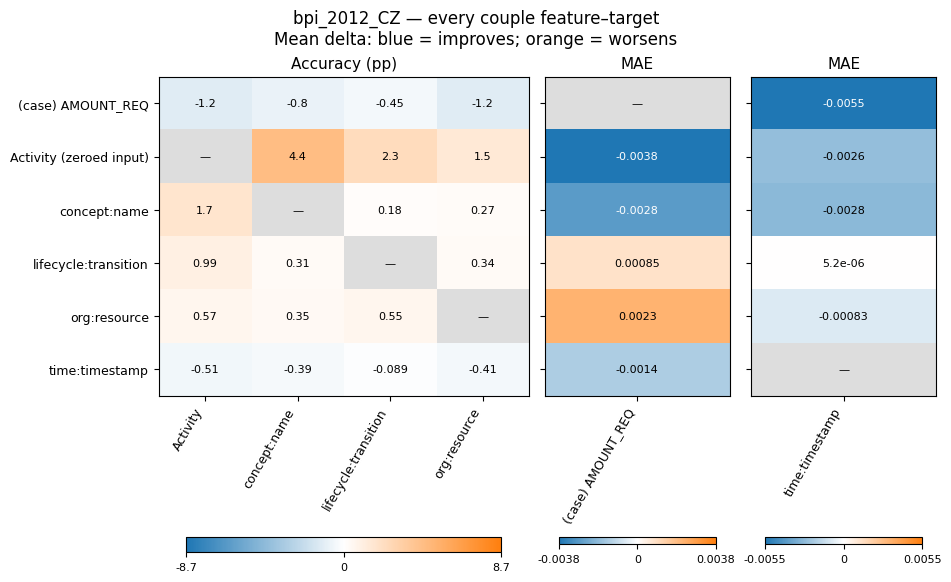

In [24]:
plot_conclusions("bpi_2012_CZ")


The removal of `(case) AMOUNT_REQ` is the more frequent case of improvement in this dataset. On the 25 comparisons, 23 show a significant improvement and no worsening. For `Activity`, `lifecycle_transition`, `org:resource` and `time:timestamp` the improvements are meaningful in every pattern

#### BPI 2013

In this dataset the worsenings are more numerous than the improvements

In [25]:
readable.loc[readable.log.eq("bpi_2013_CZ"), list(columns)].rename(columns=columns)


,Removed feature,Target,Unit,Mean Delta,Minimum Delta,Maximum Delta,Improves,Worsens,Inconclusive,Not estimable
120,Activity (zeroed input),concept:name,pp,3.8001,1.2740,12.7224,0,4,1,0
121,Activity (zeroed input),impact,pp,0.3810,0.0296,1.0853,0,0,5,0
122,Activity (zeroed input),lifecycle:transition,pp,3.1483,-0.8284,14.8404,0,1,4,0
123,Activity (zeroed input),org:group,pp,0.3892,-0.2163,1.4130,0,0,5,0
124,Activity (zeroed input),org:resource,pp,2.2572,0.6319,3.6747,0,2,3,0
...,...,...,...,...,...,...,...,...,...,...
247,time:timestamp,org:role,pp,2.5443,1.8705,3.1360,0,0,5,0
248,time:timestamp,organization country,pp,0.9132,0.5333,1.2500,0,2,3,0
249,time:timestamp,organization involved,pp,6.4221,3.6631,7.8641,0,4,1,0
250,time:timestamp,product,pp,5.6912,5.1479,6.1538,0,2,3,0


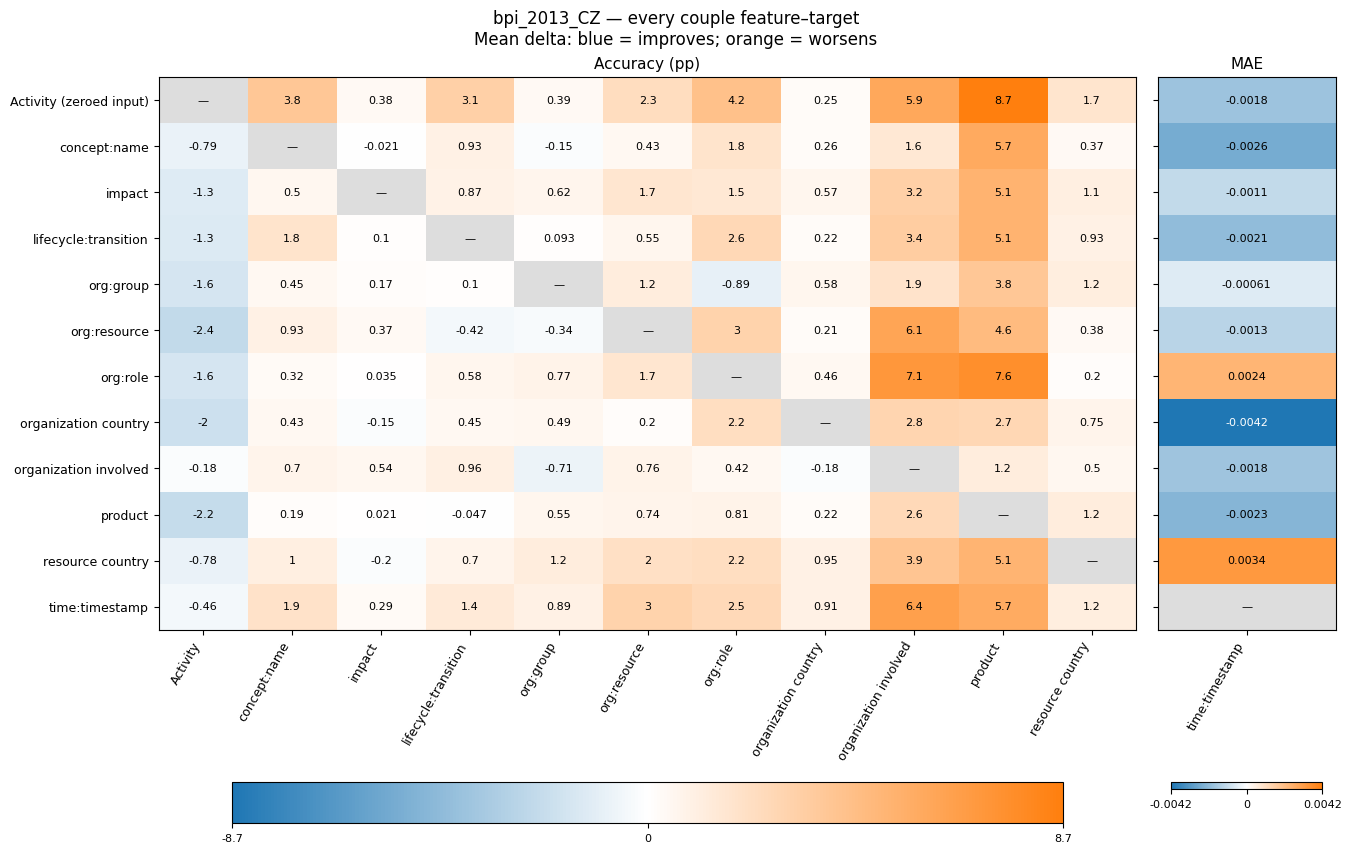

In [26]:
plot_conclusions("bpi_2013_CZ")


`product` and `organization_involved` are often penalized from the removals and both the worsenings are significative in all five patterns. For example, without `org:role` 

#### SP 2020

In [27]:
readable.loc[readable.log.eq("sp2020_CZ"), list(columns)].rename(columns=columns)


,Removed feature,Target,Unit,Mean Delta,Minimum Delta,Maximum Delta,Improves,Worsens,Inconclusive,Not estimable
252,Activity (zeroed input),DEVICETYPE,pp,-0.0846,-0.2532,0.0046,0,0,5,0
253,Activity (zeroed input),REPAIR_IN_TIME_5D,pp,-0.0368,-0.2373,0.0531,0,0,2,3
254,Activity (zeroed input),org:resource,pp,0.1789,-0.0052,0.6251,0,2,3,0
255,Activity (zeroed input),time:timestamp,MAE,0.0003,0.0001,0.0004,0,0,5,0
256,DEVICETYPE,Activity,pp,-0.9134,-1.1160,-0.7306,5,0,0,0
257,DEVICETYPE,REPAIR_IN_TIME_5D,pp,-0.0153,-0.1089,0.0325,0,0,2,3
258,DEVICETYPE,org:resource,pp,-0.0354,-0.1541,0.0000,0,0,3,2
259,DEVICETYPE,time:timestamp,MAE,-0.0009,-0.0011,-0.0008,0,0,5,0
260,REPAIR_IN_TIME_5D,Activity,pp,-0.3355,-0.4820,-0.1285,0,0,5,0
261,REPAIR_IN_TIME_5D,DEVICETYPE,pp,-0.1698,-0.3616,-0.0323,2,0,3,0


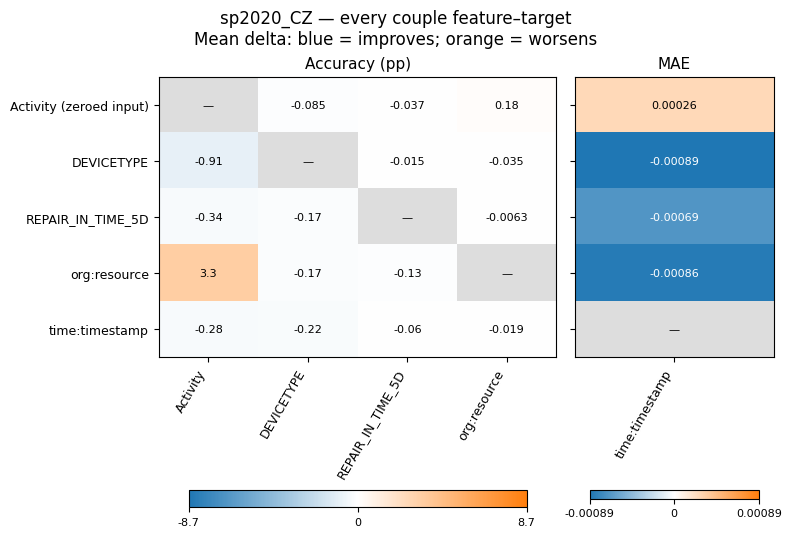

In [28]:
plot_conclusions("sp2020_CZ")


#### BPI 2020 - Request for Payment

In [29]:
readable.loc[readable.log.eq("BPI20_RequestForPayment_CZ"), list(columns)].rename(columns=columns)


,Removed feature,Target,Unit,Mean Delta,Minimum Delta,Maximum Delta,Improves,Worsens,Inconclusive,Not estimable
0,Activity (zeroed input),case:Activity,pp,-0.2478,-0.7542,0.0000,0,0,2,3
1,Activity (zeroed input),case:OrganizationalEntity,pp,1.4638,1.0550,2.7246,0,3,2,0
2,Activity (zeroed input),case:Project,pp,1.8434,1.3996,3.0497,0,1,4,0
3,Activity (zeroed input),case:RequestedAmount,MAE,0.0334,0.0256,0.0413,0,2,3,0
4,Activity (zeroed input),case:RfpNumber,pp,0.0050,0.0000,0.0252,0,0,1,4
...,...,...,...,...,...,...,...,...,...,...
85,time:timestamp,case:RequestedAmount,MAE,-0.0650,-0.1518,0.0015,2,0,3,0
86,time:timestamp,case:RfpNumber,pp,-0.0140,-0.0701,0.0000,0,0,1,4
87,time:timestamp,case:Task,pp,-0.0374,-0.1109,0.0064,0,0,5,0
88,time:timestamp,org:resource,pp,0.4353,0.0212,1.6182,0,2,3,0


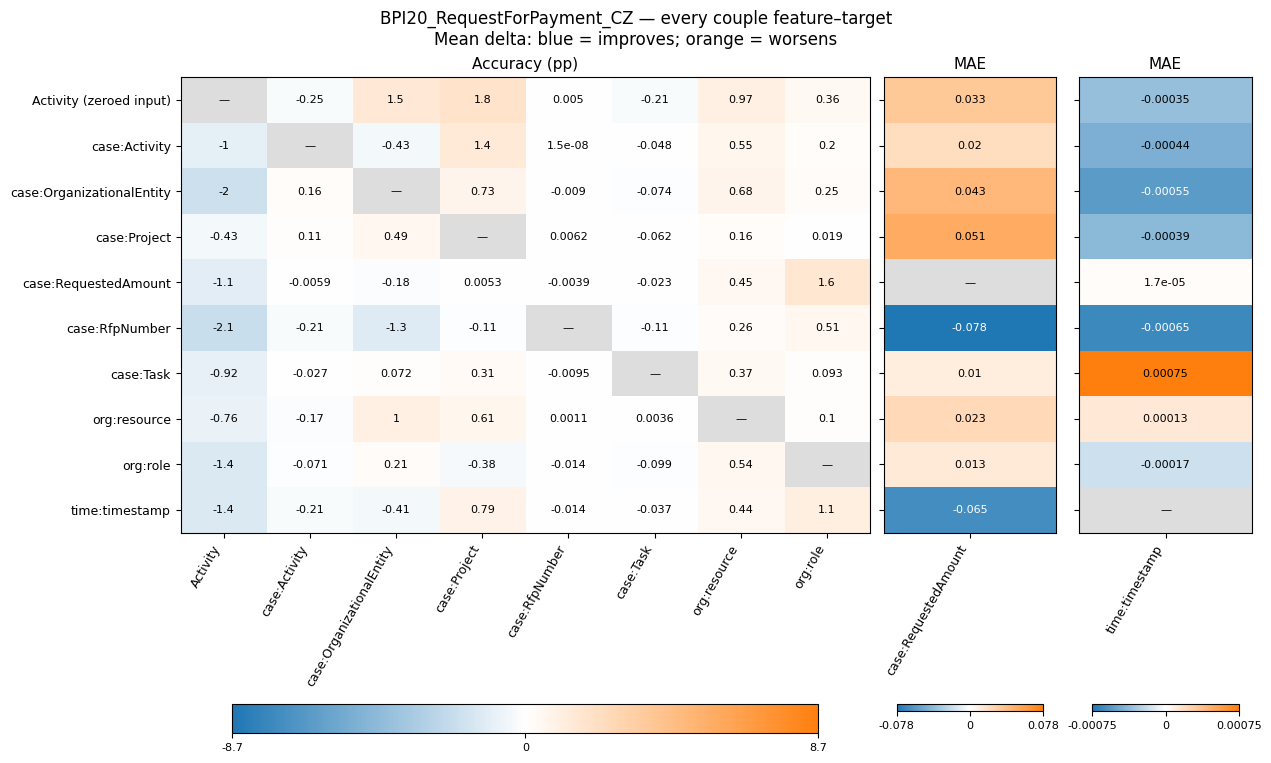

In [30]:
plot_conclusions("BPI20_RequestForPayment_CZ")
